In [1]:
import zipfile
import os

# Extract the uploaded ZIP file
with zipfile.ZipFile('/content/archive (1).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

# Show extracted files
os.listdir('/content/')

['.config', 'Mall_Customers.csv', 'archive (1).zip', 'sample_data']

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/Mall_Customers.csv')

# Display first 5 rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
df.describe()

Dataset Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
# Select numerical features for PCA and clustering
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

X = df[features]

# Display selected features
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [7]:
print("Selected Features Shape:", X.shape)

Selected Features Shape: (200, 3)


In [8]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the selected features
X_scaled = scaler.fit_transform(X)

# Display the standardized data
print(X_scaled[:5])

print("\nScaled Data Shape:", X_scaled.shape)

[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]

Scaled Data Shape: (200, 3)


In [10]:
from sklearn.decomposition import PCA

# Apply PCA and reduce to 2 components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Display PCA results
print("PCA Data Shape:", X_pca.shape)

print("\nFirst 5 PCA values:")
print(X_pca[:5])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())

PCA Data Shape: (200, 2)

First 5 PCA values:
[[-0.61572002 -1.76348088]
 [-1.66579271 -1.82074695]
 [ 0.33786191 -1.67479894]
 [-1.45657325 -1.77242992]
 [-0.03846521 -1.66274012]]

Explained Variance Ratio:
[0.44266167 0.33308378]

Total Variance Explained:
0.7757454566976747


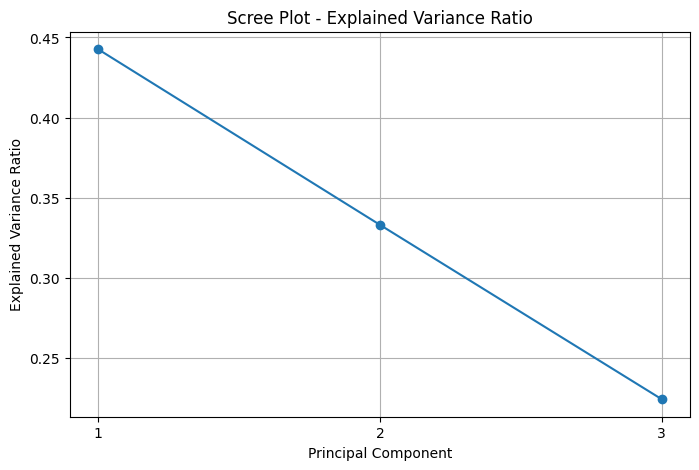

Explained Variance Ratio: [0.44266167 0.33308378 0.22425454]
Cumulative Explained Variance: [0.44266167 0.77574546 1.        ]


In [11]:
# PCA with all 3 components
pca_full = PCA(n_components=3)

X_pca_full = pca_full.fit_transform(X_scaled)

# Explained variance ratio
explained_variance = pca_full.explained_variance_ratio_

# Plot Scree Plot
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 4),
    explained_variance,
    marker='o'
)

plt.title('Scree Plot - Explained Variance Ratio')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks([1, 2, 3])
plt.grid(True)

plt.show()

# Print variance values
print("Explained Variance Ratio:", explained_variance)

print("Cumulative Explained Variance:",
      np.cumsum(explained_variance))

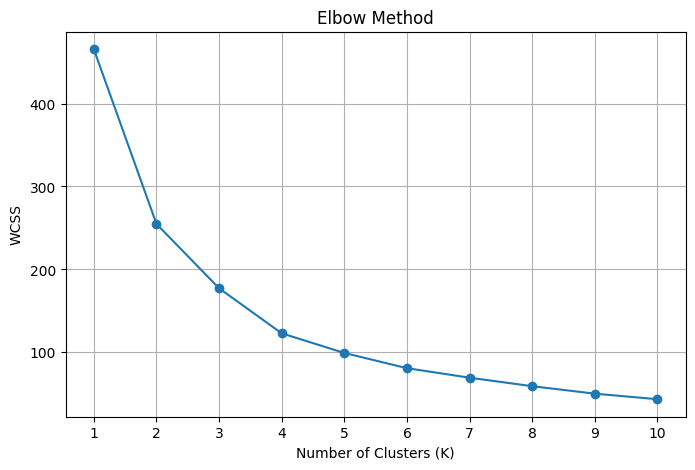

In [12]:
from sklearn.cluster import KMeans

# Calculate WCSS (inertia) for different K values
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

K = 2, Silhouette Score = 0.4256
K = 3, Silhouette Score = 0.4136
K = 4, Silhouette Score = 0.4209
K = 5, Silhouette Score = 0.3931
K = 6, Silhouette Score = 0.3775
K = 7, Silhouette Score = 0.3871
K = 8, Silhouette Score = 0.3976
K = 9, Silhouette Score = 0.3899
K = 10, Silhouette Score = 0.4038


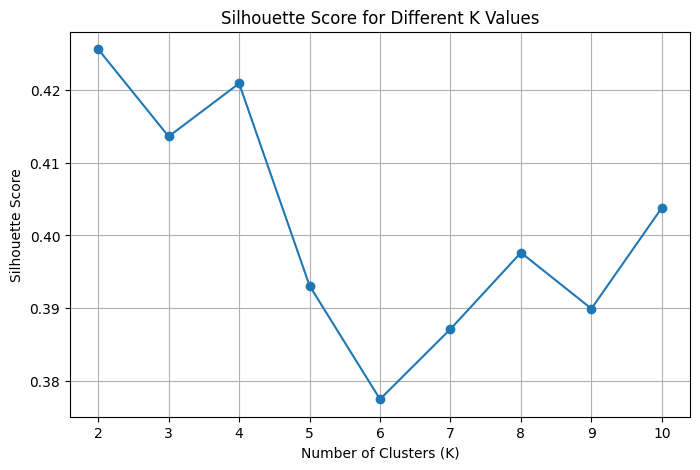

In [13]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

# Calculate Silhouette Score for K = 2 to 10
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [14]:
# Choose the optimal number of clusters
optimal_k = 4

# Create and train K-Means
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign cluster labels
df['Cluster'] = kmeans_final.fit_predict(X_pca)

# Display cluster assignments
df[['Age', 'Annual Income (k$)',
    'Spending Score (1-100)', 'Cluster']].head(10)

,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,19,15,39,2
1,21,15,81,2
2,20,16,6,0
3,23,16,77,2
4,31,17,40,2
5,22,17,76,2
6,35,18,6,0
7,23,18,94,2
8,64,19,3,0
9,30,19,72,2


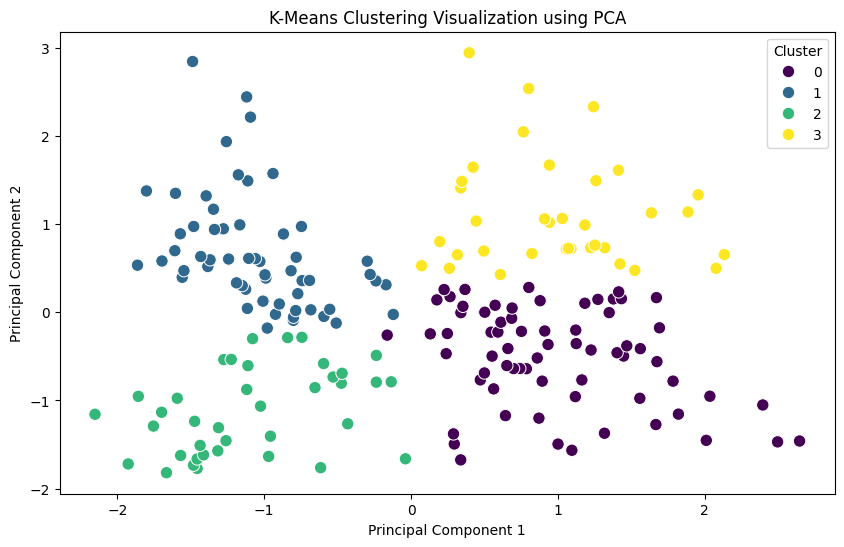

In [16]:
# Visualize K-Means clusters using PCA components
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    s=80
)

plt.title('K-Means Clustering Visualization using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

plt.show()

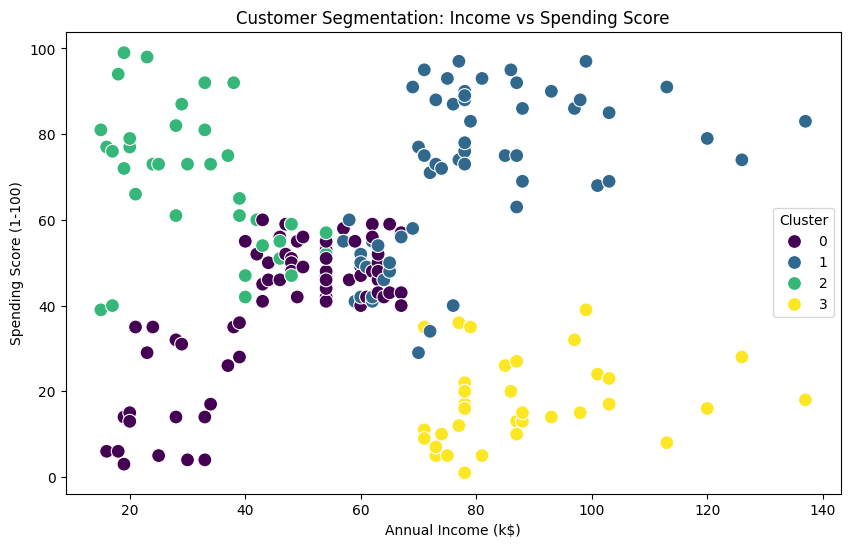

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title('Customer Segmentation: Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.show()

In [18]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_pca)

# Add DBSCAN labels to dataset
df['DBSCAN_Cluster'] = dbscan_labels

# Display cluster labels
print("DBSCAN Cluster Labels:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN Cluster Labels:
DBSCAN_Cluster
-1     15
 0    185
Name: count, dtype: int64


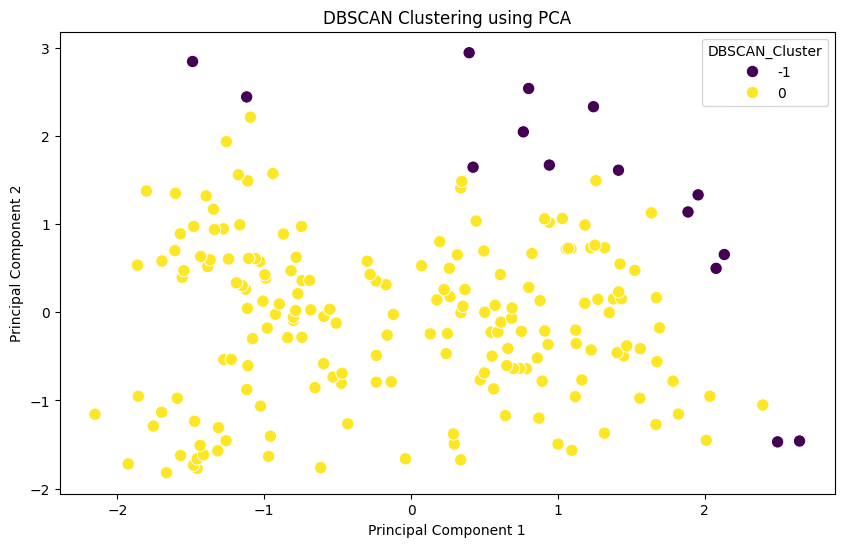

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['DBSCAN_Cluster'],
    palette='viridis',
    s=80
)

plt.title('DBSCAN Clustering using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

In [20]:
from sklearn.cluster import AgglomerativeClustering

# Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=4)

hierarchical_labels = hierarchical.fit_predict(X_pca)

# Add cluster labels to dataset
df['Hierarchical_Cluster'] = hierarchical_labels

# Display cluster counts
print("Hierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    97
1    49
2    26
3    28
Name: count, dtype: int64


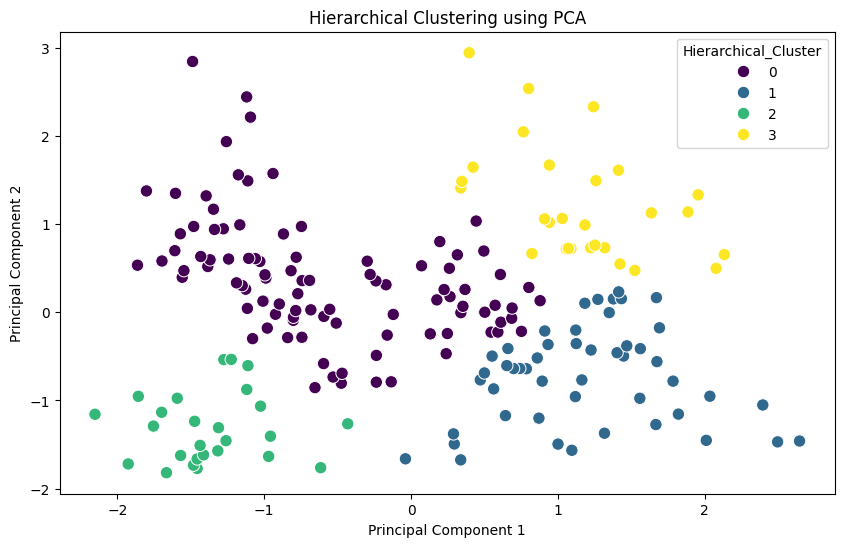

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Hierarchical_Cluster'],
    palette='viridis',
    s=80
)

plt.title('Hierarchical Clustering using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

Agglomerative Hierarchical Clustering was applied to group customers based on similarity. The clustering results were visualized using the first two principal components. This method builds clusters by progressively merging similar data points.

In [22]:
print("K-Means Clusters:")
print(df['Cluster'].value_counts().sort_index())

print("\nDBSCAN Clusters:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

print("\nHierarchical Clusters:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

K-Means Clusters:
Cluster
0    69
1    58
2    38
3    35
Name: count, dtype: int64

DBSCAN Clusters:
DBSCAN_Cluster
-1     15
 0    185
Name: count, dtype: int64

Hierarchical Clusters:
Hierarchical_Cluster
0    97
1    49
2    26
3    28
Name: count, dtype: int64


## Conclusion

In this project, dimensionality reduction and unsupervised clustering techniques were applied to the Mall Customer Segmentation dataset.

The numerical features were standardized using StandardScaler. Principal Component Analysis (PCA) was used to reduce the dimensionality of the data and visualize the explained variance ratio through a Scree Plot.

K-Means clustering was performed, and the optimal number of clusters was analyzed using the Elbow Method and Silhouette Score. The resulting clusters were visualized using PCA-based scatter plots.

DBSCAN and Hierarchical Clustering were also implemented to compare different unsupervised clustering approaches.

This project demonstrates how dimensionality reduction and clustering can be used to identify customer groups and understand patterns in customer income and spending behavior.